# Sumativa 3 · Punto 3 · Impacto de la imputación sobre el modelo final

**MCDI501 · Estadística Computacional para la Toma de Decisiones · Grupo 6**

Responsable de esta sección: **Jorge Álvarez Ossandón**

Docente: Jean Paul Maidana González · Universidad Andrés Bello · UNAB Online

---

## Qué cubre este cuaderno

El punto 1 eligió la imputación por regresión (E3) como conjunto base, y el punto 2 ajustó sobre él el modelo final **M2** (sexo, área, jornada y edad de ingreso). Este cuaderno pone esa elección a prueba: reajusta **la misma especificación** sobre los tres conjuntos y mide qué cambia.

1. Replicar el M2 del punto 2 sobre E3, como control.
2. Definir un conjunto de prueba **común** con atraso **observado**, para que las métricas sean comparables.
3. Reajustar el M2 sobre E1 (eliminación), E2 (imputación simple) y E3 (imputación por regresión).
4. Comparar los odds ratios.
5. Comparar la amplitud de los intervalos de confianza.
6. Comparar el desempeño: AUC, exactitud, sensibilidad y especificidad.
7. Repetir la comparación en la jornada A Distancia, donde se imputa el 76 %.
8. Análisis de sensibilidad con imputación múltiple (reglas de Rubin).

In [1]:
# PASO 1 · Replicar el M2 de la parte 2 sobre E3 (control)
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, accuracy_score
import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# A. Raíz del repo y carpeta de resultados
RAIZ = Path.cwd()
while not (RAIZ / "S3").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
RES = RAIZ / "S3" / "resultados"
FIG = RAIZ / "S3" / "informe" / "figuras"
SEMILLA = 42

# B. Variables derivadas, idénticas a la parte 2
def preparar(d):
    d = d.copy()
    d["sexo"] = d["gen_alu"].map({1: "Hombre", 2: "Mujer"})
    d["edad_ingreso"] = d["anio_ing_carr_act"] - d["fec_nac_alu"] // 100
    return d

PREDICTORAS = ["sexo", "area_conocimiento", "jornada", "edad_ingreso"]

# C. Matriz de diseño con columnas fijas
def matriz(d, columnas=None):
    X = sm.add_constant(pd.get_dummies(d[PREDICTORAS], drop_first=True, dtype=int), has_constant="add")
    if columnas is not None:
        X = X.reindex(columns=columnas, fill_value=0)
    return X.astype(float)

train_e3 = preparar(pd.read_parquet(RES / "train_e3.parquet"))
test_e3 = preparar(pd.read_parquet(RES / "test_e3.parquet"))

X_tr = matriz(train_e3)
COLUMNAS = list(X_tr.columns)          # se usan en todos los conjuntos
X_te = matriz(test_e3, COLUMNAS)
y_tr = train_e3["atraso_alto"].astype(int)
y_te = test_e3["atraso_alto"].astype(int)

# D. Ajuste, umbral de Youden (entrenamiento) y evaluación (prueba)
m2_e3 = sm.Logit(y_tr, X_tr).fit(disp=False)

p_tr = m2_e3.predict(X_tr)
fpr, tpr, umbrales = roc_curve(y_tr, p_tr)
umbral = umbrales[np.argmax(tpr - fpr)]

p_te = m2_e3.predict(X_te)
pred = (p_te >= umbral).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()

print(f"Columnas del modelo: {len(COLUMNAS)} (constante incluida)")
print(f"AIC = {m2_e3.aic:.1f} | BIC = {m2_e3.bic:.1f} | Pseudo R² = {m2_e3.prsquared:.4f}")
print(f"AUC prueba = {roc_auc_score(y_te, p_te):.4f} | Umbral Youden = {umbral:.4f}")
print(f"Sensibilidad = {tp/(tp+fn):.4f} | Especificidad = {tn/(tn+fp):.4f} | Exactitud = {accuracy_score(y_te, pred):.4f}")

# Comparación con lo que guardó la parte 2
cesar = pd.read_csv(RES / "logistica_odds_ratios.csv", index_col="Variable")["OR"]
control = pd.DataFrame({"OR parte 2": cesar, "OR replicado": np.exp(m2_e3.params).round(4)}).dropna()
control["diferencia"] = (control["OR replicado"] - control["OR parte 2"]).abs()
print(f"\nDiferencia máxima en OR: {control['diferencia'].max():.4f}")
control

Columnas del modelo: 16 (constante incluida)
AIC = 75422.0 | BIC = 75569.3 | Pseudo R² = 0.0667
AUC prueba = 0.6756 | Umbral Youden = 0.2246
Sensibilidad = 0.5950 | Especificidad = 0.6787 | Exactitud = 0.6587

Diferencia máxima en OR: 0.0104


,OR parte 2,OR replicado,diferencia
area_conocimiento_Agropecuaria,2.4189,2.4208,0.0019
area_conocimiento_Arte y Arquitectura,1.1909,1.1908,0.0001
area_conocimiento_Ciencias Básicas,2.0260,2.0278,0.0018
area_conocimiento_Ciencias Sociales,0.5779,0.5787,0.0008
area_conocimiento_Derecho,4.4228,4.4259,0.0031
area_conocimiento_Educación,0.7002,0.7004,0.0002
area_conocimiento_Humanidades,1.1598,1.1702,0.0104
area_conocimiento_Salud,0.9178,0.9187,0.0009
area_conocimiento_Tecnología,2.1392,2.1403,0.0011
edad_ingreso,1.0349,1.0349,0.0000


In [2]:
# PASO 2 · Partición común y test con atraso observado
from sklearn.model_selection import train_test_split

e1 = pd.read_parquet(RES / "e1_eliminacion.parquet")
e2 = pd.read_parquet(RES / "e2_simple.parquet")
e3 = pd.read_parquet(RES / "e3_regresion.parquet")

# A. E2 y E3 deben venir en el mismo orden (mismas personas, fila a fila).
#    .equals() trata dos NaN en la misma posición como iguales; == no.
CLAVE = ["mrun", "fec_nac_alu", "area_conocimiento"]
print(f"mrun vacíos en E3: {e3['mrun'].isna().sum():,}")
mismo_orden = len(e2) == len(e3) and e2[CLAVE].reset_index(drop=True).equals(e3[CLAVE].reset_index(drop=True))
print(f"¿E2 y E3 en el mismo orden? {mismo_orden}")
assert mismo_orden

# B. Casos observados: tienen año y semestre de ingreso original
obs = e3[["anio_ing_carr_ori", "sem_ing_carr_ori"]].notna().all(axis=1).to_numpy()
print(f"Observados: {obs.sum():,} | Imputados: {(~obs).sum():,} | Filas E1: {len(e1):,}")
assert obs.sum() == len(e1)

# C. Reconstruir la partición de la parte 1 (misma semilla y estratificación)
pos = np.arange(len(e3))
pos_tr, pos_te = train_test_split(pos, test_size=0.30, random_state=SEMILLA,
                                  stratify=e3["atraso_alto"].astype(int))
test_ref = pd.read_parquet(RES / "test_e3.parquet")
misma = e3[CLAVE].iloc[pos_te].reset_index(drop=True).equals(test_ref[CLAVE].reset_index(drop=True))
print(f"¿La partición coincide con test_e3 de la parte 1? {misma}")
assert misma

# D. Conjuntos de entrenamiento: cada estrategia con su versión de las filas
tr_obs = pos_tr[obs[pos_tr]]
conjuntos_tr = {
    "E1 · Eliminación": preparar(e3.iloc[tr_obs]),        # solo observados
    "E2 · Imputación simple": preparar(e2.iloc[pos_tr]),  # todos, con mediana
    "E3 · Imputación por regresión": preparar(e3.iloc[pos_tr]),  # todos, con regresión
}

# E. Test común (atraso real) y test de imputados (para el paso 7)
test_comun = preparar(e3.iloc[pos_te[obs[pos_te]]])
test_imput = {"E2": preparar(e2.iloc[pos_te[~obs[pos_te]]]),
              "E3": preparar(e3.iloc[pos_te[~obs[pos_te]]])}

resumen = pd.DataFrame([{"Conjunto": k, "n": len(d),
                         "% atraso alto": round(100 * d["atraso_alto"].astype(int).mean(), 2)}
                        for k, d in {**{f"Entrenamiento {k}": v for k, v in conjuntos_tr.items()},
                                     "Prueba común (observados)": test_comun,
                                     "Prueba imputados según E2": test_imput["E2"],
                                     "Prueba imputados según E3": test_imput["E3"]}.items()])
resumen

mrun vacíos en E3: 7
¿E2 y E3 en el mismo orden? True
Observados: 91,667 | Imputados: 13,396 | Filas E1: 91,667
¿La partición coincide con test_e3 de la parte 1? True


,Conjunto,n,% atraso alto
0,Entrenamiento E1 · Eliminación,64159,24.54
1,Entrenamiento E2 · Imputación simple,73544,32.66
2,Entrenamiento E3 · Imputación por regresión,73544,23.84
3,Prueba común (observados),27508,24.53
4,Prueba imputados según E2,4011,89.58
5,Prueba imputados según E3,4011,19.07


In [3]:
# PASO 3 · Reajustar el M2 en E1, E2 y E3
modelos, umbrales_youden, prob_comun = {}, {}, {}
X_comun = matriz(test_comun, COLUMNAS)
y_comun = test_comun["atraso_alto"].astype(int)

filas = []
for nombre, d in conjuntos_tr.items():
    X = matriz(d, COLUMNAS)
    y = d["atraso_alto"].astype(int)
    m = sm.Logit(y, X).fit(disp=False, maxiter=100)

    # Umbral de Youden con su propio entrenamiento
    fpr, tpr, u = roc_curve(y, m.predict(X))
    umbrales_youden[nombre] = u[np.argmax(tpr - fpr)]

    modelos[nombre] = m
    prob_comun[nombre] = m.predict(X_comun)

    dummies = X.drop(columns=["const", "edad_ingreso"])
    filas.append({"Conjunto": nombre, "n": len(d),
                  "Mín. casos por dummy": int(dummies.sum().min()),
                  "Convergió": m.mle_retvals["converged"],
                  "AIC (solo ref.)": round(m.aic, 1),
                  "Pseudo R²": round(m.prsquared, 4),
                  "Umbral Youden": round(umbrales_youden[nombre], 4)})

ajustes = pd.DataFrame(filas).set_index("Conjunto")
ajustes

,n,Mín. casos por dummy,Convergió,AIC (solo ref.),Pseudo R²,Umbral Youden
Conjunto,,,,,,
E1 · Eliminación,64159,198,True,67290.2,0.0594,0.2294
E2 · Imputación simple,73544,398,True,79491.9,0.1449,0.3011
E3 · Imputación por regresión,73544,398,True,75422.0,0.0667,0.2246


Cambio absoluto medio vs E1: {'E2': '27.1 %', 'E3': '18.5 %'}
Variables que cambian de lado del 1: {'E2': ['area_conocimiento_Educación', 'jornada_Diurna', 'jornada_Otra', 'jornada_Vespertina'], 'E3': ['jornada_Semipresencial']}
Variables que cambian de significancia: {'E2': ['jornada_Otra'], 'E3': ['jornada_Otra', 'jornada_Semipresencial']}


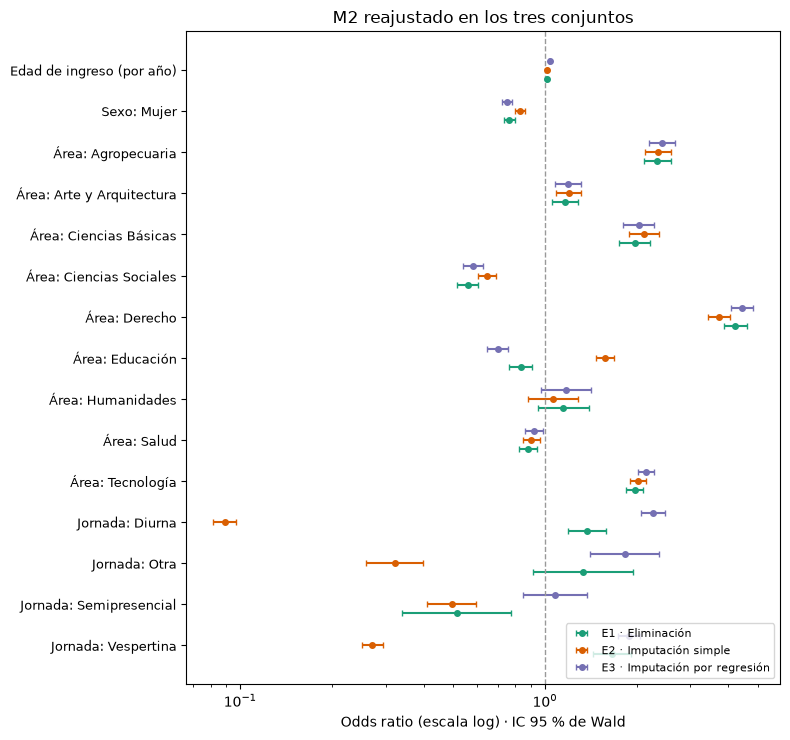

E1                   E2                   E3                           E2                                                       E3                       \
                                          OR IC inf IC sup     OR IC inf IC sup     OR IC inf IC sup Cambio % vs E1 Cambia de lado del 1 Cambia significancia Cambio % vs E1 Cambia de lado del 1   
edad_ingreso                           1.013  1.009  1.018  1.016  1.012  1.019  1.035  1.031  1.039          0.212                False                False          2.126                False   
sexo_Mujer                             0.764  0.734  0.795  0.830  0.800  0.862  0.749  0.721  0.778          8.647                False                False         -2.021                False   
area_conocimiento_Agropecuaria         2.337  2.108  2.590  2.351  2.129  2.595  2.421  2.192  2.673          0.587                False                False          3.591                False   
area_conocimiento_Arte y Arquitectura  1.162  1.052  1.284  1.195  1.085  1.316  1.191  1.080  1.313          2.865                False                False          2.482                False   
area_conocimiento_Ciencias Básicas     1.968  1.746  2.218  2.112  1.880  2.373  2.028  1.804  2.279          7.333                False                False          3.053                False   
area_conocimiento_Ciencias Sociales    0.557  0.513  0.605  0.646  0.603  0.691  0.579  0.536  0.624         15.861                False                False          3.859                False   
area_conocimiento_Derecho              4.213  3.861  4.597  3.724  3.425  4.050  4.426  4.069  4.814        -11.593                False                False          5.057                False   
area_conocimiento_Educación            0.833  0.764  0.907  1.579  1.475  1.689  0.700  0.647  0.758         89.575                 True                False        -15.885                False   
area_conocimiento_Humanidades          1.150  0.952  1.390  1.064  0.879  1.288  1.170  0.970  1.411         -7.463                False                False          1.759                False   
area_conocimiento_Salud                0.879  0.820  0.943  0.903  0.845  0.964  0.919  0.859  0.983          2.646                False                False          4.484                False   
area_conocimiento_Tecnología           1.971  1.846  2.104  2.020  1.904  2.142  2.140  2.016  2.272          2.502                False                False          8.616                False   
jornada_Diurna                         1.375  1.189  1.590  0.089  0.082  0.097  2.263  2.068  2.476        -93.536                 True                False         64.519                False   
jornada_Otra                           1.334  0.917  1.942  0.321  0.259  0.398  1.824  1.402  2.374        -75.942                 True                 True         36.720                False   
jornada_Semipresencial                 0.513  0.340  0.773  0.495  0.411  0.595  1.077  0.845  1.371         -3.581                False                False        109.893                 True   
jornada_Vespertina                     1.658  1.439  1.910  0.271  0.251  0.294  1.882  1.731  2.047        -83.626                 True                False         13.559                False   

                                                            
                                      Cambia significancia  
edad_ingreso                                         False  
sexo_Mujer                                           False  
area_conocimiento_Agropecuaria                       False  
area_conocimiento_Arte y Arquitectura                False  
area_conocimiento_Ciencias Básicas                   False  
area_conocimiento_Ciencias Sociales                  False  
area_conocimiento_Derecho                            False  
area_conocimiento_Educación                          False  
area_conocimiento_Humanidades                        False  
area_conocimiento_Sal

In [4]:
# PASO 4 · Comparación de odds ratios (referencia: E1)
nombres = list(modelos)
ref = nombres[0]                                   # E1 · Eliminación
corto = {n: n.split(" · ")[0] for n in nombres}    # E1, E2, E3

tabla = {}
for n, m in modelos.items():
    ic = np.exp(m.conf_int())
    tabla[(corto[n], "OR")] = np.exp(m.params)
    tabla[(corto[n], "IC inf")] = ic[0]
    tabla[(corto[n], "IC sup")] = ic[1]
tabla_or = pd.DataFrame(tabla).drop(index="const")

for e in ["E2", "E3"]:
    tabla_or[(e, "Cambio % vs E1")] = 100 * (tabla_or[(e, "OR")] / tabla_or[("E1", "OR")] - 1)
    tabla_or[(e, "Cambia de lado del 1")] = np.sign(np.log(tabla_or[(e, "OR")])) != np.sign(np.log(tabla_or[("E1", "OR")]))
    sig_e1 = (tabla_or[("E1", "IC inf")] > 1) | (tabla_or[("E1", "IC sup")] < 1)
    sig_e = (tabla_or[(e, "IC inf")] > 1) | (tabla_or[(e, "IC sup")] < 1)
    tabla_or[(e, "Cambia significancia")] = sig_e1 != sig_e

print("Cambio absoluto medio vs E1:",
      {e: f"{tabla_or[(e, 'Cambio % vs E1')].abs().mean():.1f} %" for e in ["E2", "E3"]})
print("Variables que cambian de lado del 1:",
      {e: list(tabla_or.index[tabla_or[(e, 'Cambia de lado del 1')]]) for e in ["E2", "E3"]})
print("Variables que cambian de significancia:",
      {e: list(tabla_or.index[tabla_or[(e, 'Cambia significancia')]]) for e in ["E2", "E3"]})

# Gráfico forest
etiquetas = [v.replace("area_conocimiento_", "Área: ").replace("jornada_", "Jornada: ")
              .replace("sexo_", "Sexo: ").replace("edad_ingreso", "Edad de ingreso (por año)")
             for v in tabla_or.index]
colores = {"E1": "#1b9e77", "E2": "#d95f02", "E3": "#7570b3"}
desplaz = {"E1": -0.22, "E2": 0.0, "E3": 0.22}
fig, ax = plt.subplots(figsize=(8, 7.5))
yy = np.arange(len(tabla_or))[::-1]
for e in ["E1", "E2", "E3"]:
    orr = tabla_or[(e, "OR")].values
    err = [orr - tabla_or[(e, "IC inf")].values, tabla_or[(e, "IC sup")].values - orr]
    ax.errorbar(orr, yy + desplaz[e], xerr=err, fmt="o", ms=4, capsize=2,
                color=colores[e], label=[n for n in nombres if n.startswith(e)][0])
ax.axvline(1, color="#999999", ls="--", lw=1)
ax.set_xscale("log")
ax.set_yticks(yy)
ax.set_yticklabels(etiquetas, fontsize=9)
ax.set_xlabel("Odds ratio (escala log) · IC 95 % de Wald")
ax.set_title("M2 reajustado en los tres conjuntos")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "s3_05_or_por_estrategia.png", dpi=150)
plt.show()

tabla_or.round(3)

In [5]:
cols = [(e, "OR") for e in ["E1", "E2", "E3"]] + [("E2", "Cambio % vs E1"), ("E3", "Cambio % vs E1")]
tabla_or[cols].round(3)

,E1,E2,E3,E2,E3
,OR,OR,OR,Cambio % vs E1,Cambio % vs E1
edad_ingreso,1.013,1.016,1.035,0.212,2.126
sexo_Mujer,0.764,0.830,0.749,8.647,-2.021
area_conocimiento_Agropecuaria,2.337,2.351,2.421,0.587,3.591
area_conocimiento_Arte y Arquitectura,1.162,1.195,1.191,2.865,2.482
area_conocimiento_Ciencias Básicas,1.968,2.112,2.028,7.333,3.053
area_conocimiento_Ciencias Sociales,0.557,0.646,0.579,15.861,3.859
area_conocimiento_Derecho,4.213,3.724,4.426,-11.593,5.057
area_conocimiento_Educación,0.833,1.579,0.700,89.575,-15.885
area_conocimiento_Humanidades,1.150,1.064,1.170,-7.463,1.759


In [6]:
# PASO 4b · ¿Qué atraso le asignó cada imputación a cada jornada?
imp = ~obs
diag = pd.DataFrame({
    "n observados": e3[obs].groupby("jornada").size(),
    "n imputados": e3[imp].groupby("jornada").size(),
    "% imputado": (100 * e3.assign(i=imp).groupby("jornada")["i"].mean()).round(1),
    "% atraso alto observados": (100 * e3[obs].groupby("jornada")["atraso_alto"].mean().astype(float)).round(1),
    "% atraso alto imputados E2": (100 * e2[imp].groupby("jornada")["atraso_alto"].mean().astype(float)).round(1),
    "% atraso alto imputados E3": (100 * e3[imp].groupby("jornada")["atraso_alto"].mean().astype(float)).round(1),
})
diag

,n observados,n imputados,% imputado,% atraso alto observados,% atraso alto imputados E2,% atraso alto imputados E3
jornada,,,,,,
A Distancia,2182,6882,75.9,22.6,97.8,19.2
Diurna,81001,1196,1.5,23.9,29.7,19.8
Otra,263,280,51.6,22.4,79.3,17.1
Semipresencial,380,448,54.1,10.5,99.8,21.2
Vespertina,7841,4590,36.9,32.9,89.7,18.5


In [7]:
# PASO 5 · Amplitud de los intervalos de confianza (escala log)
anchos = {}
for nombre, d in conjuntos_tr.items():
    X = matriz(d, COLUMNAS)
    y = d["atraso_alto"].astype(int)
    grupos = pd.factorize(d["nomb_inst"])[0]
    mw = modelos[nombre]
    mc = sm.Logit(y, X).fit(disp=False, maxiter=100, cov_type="cluster", cov_kwds={"groups": grupos})
    e = corto[nombre]
    anchos[(e, "Wald")] = mw.conf_int()[1] - mw.conf_int()[0]
    anchos[(e, "Cluster")] = mc.conf_int()[1] - mc.conf_int()[0]
anchos = pd.DataFrame(anchos).drop(index="const")

resumen_anchos = pd.DataFrame({
    "Ancho mediano Wald": [anchos[(e, "Wald")].median() for e in ["E1", "E2", "E3"]],
    "Ancho mediano cluster": [anchos[(e, "Cluster")].median() for e in ["E1", "E2", "E3"]],
    "Razón Wald vs E1": [(anchos[(e, "Wald")] / anchos[("E1", "Wald")]).median() for e in ["E1", "E2", "E3"]],
    "Razón cluster vs E1": [(anchos[(e, "Cluster")] / anchos[("E1", "Cluster")]).median() for e in ["E1", "E2", "E3"]],
    "Cluster / Wald": [(anchos[(e, "Cluster")] / anchos[(e, "Wald")]).median() for e in ["E1", "E2", "E3"]],
}, index=["E1", "E2", "E3"]).round(3)
print(f"Razón esperada solo por tamaño (E2/E3 vs E1): {np.sqrt(len(conjuntos_tr[ref]) / 73544):.3f}")
resumen_anchos

Razón esperada solo por tamaño (E2/E3 vs E1): 0.934


,Ancho mediano Wald,Ancho mediano cluster,Razón Wald vs E1,Razón cluster vs E1,Cluster / Wald
E1,0.199,0.811,1.000,1.000,4.495
E2,0.168,0.829,0.900,0.958,5.531
E3,0.168,0.761,0.927,0.940,4.781


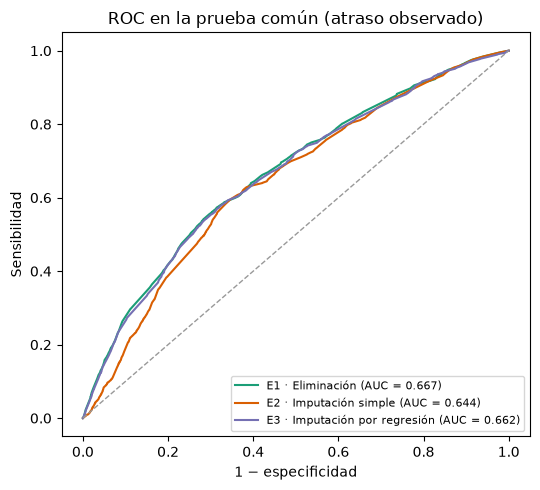

,AUC,Umbral,Sensibilidad,Especificidad,Exactitud,Prob. media predicha,% real,Δ AUC vs E1,IC95 Δ inf,IC95 Δ sup
Conjunto,,,,,,,,,,
E1 · Eliminación,0.6666,0.2294,0.5768,0.6811,0.6555,0.2457,0.2453,0.0000,NaN,NaN
E2 · Imputación simple,0.6442,0.3011,0.5599,0.6845,0.6540,0.2803,0.2453,-0.0224,-0.0273,-0.0187
E3 · Imputación por regresión,0.6617,0.2246,0.5768,0.6778,0.6530,0.2416,0.2453,-0.0049,-0.0066,-0.0032


In [8]:
# PASO 6 · Desempeño en la prueba común (atraso observado)
filas = []
for n in nombres:
    p = prob_comun[n]
    pred = (p >= umbrales_youden[n]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_comun, pred).ravel()
    filas.append({"Conjunto": n, "AUC": roc_auc_score(y_comun, p),
                  "Umbral": umbrales_youden[n],
                  "Sensibilidad": tp / (tp + fn), "Especificidad": tn / (tn + fp),
                  "Exactitud": accuracy_score(y_comun, pred),
                  "Prob. media predicha": p.mean(), "% real": y_comun.mean()})
desempeno = pd.DataFrame(filas).set_index("Conjunto")

# Bootstrap pareado de la diferencia de AUC contra E1
rng = np.random.default_rng(SEMILLA)
yv = y_comun.to_numpy()
pv = {n: np.asarray(prob_comun[n]) for n in nombres}
difs = {n: [] for n in nombres[1:]}
for b in range(500):
    i = rng.integers(0, len(yv), len(yv))
    auc_ref = roc_auc_score(yv[i], pv[ref][i])
    for n in nombres[1:]:
        difs[n].append(roc_auc_score(yv[i], pv[n][i]) - auc_ref)
desempeno["Δ AUC vs E1"] = [0.0] + [desempeno.loc[n, "AUC"] - desempeno.loc[ref, "AUC"] for n in nombres[1:]]
desempeno["IC95 Δ inf"] = [np.nan] + [np.percentile(difs[n], 2.5) for n in nombres[1:]]
desempeno["IC95 Δ sup"] = [np.nan] + [np.percentile(difs[n], 97.5) for n in nombres[1:]]

# Curvas ROC
fig, ax = plt.subplots(figsize=(5.5, 5))
for n in nombres:
    fpr, tpr, _ = roc_curve(y_comun, prob_comun[n])
    ax.plot(fpr, tpr, color=colores[corto[n]], label=f"{n} (AUC = {desempeno.loc[n, 'AUC']:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="#999999", lw=1)
ax.set_xlabel("1 − especificidad")
ax.set_ylabel("Sensibilidad")
ax.set_title("ROC en la prueba común (atraso observado)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "s3_06_roc_por_estrategia.png", dpi=150)
plt.show()

desempeno.round(4)

In [9]:
# PASO 7 · Calibración y AUC por jornada en la prueba común
d = test_comun[["jornada"]].copy()
d["real"] = y_comun.to_numpy()
for n in nombres:
    d[corto[n]] = np.asarray(prob_comun[n])

calib = d.groupby("jornada").agg(n=("real", "size"), real=("real", "mean"),
                                 E1=("E1", "mean"), E2=("E2", "mean"), E3=("E3", "mean"))
for e in ["E1", "E2", "E3"]:
    calib[f"Sesgo {e} (pp)"] = 100 * (calib[e] - calib["real"])
    calib[f"AUC {e}"] = [roc_auc_score(g["real"], g[e]) if g["real"].nunique() == 2 else np.nan
                         for _, g in d.groupby("jornada")]
calib["% imputado (en el total)"] = diag["% imputado"]
calib[["real", "E1", "E2", "E3"]] = 100 * calib[["real", "E1", "E2", "E3"]]
calib.round(2)

,n,real,E1,E2,E3,Sesgo E1 (pp),AUC E1,Sesgo E2 (pp),AUC E2,Sesgo E3 (pp),AUC E3,% imputado (en el total)
jornada,,,,,,,,,,,,
A Distancia,690,24.35,22.47,79.85,19.40,-1.88,0.55,55.50,0.50,-4.95,0.51,75.9
Diurna,24280,23.81,23.91,23.88,23.84,0.10,0.67,0.07,0.66,0.03,0.67,1.5
Otra,65,24.62,20.76,48.34,21.58,-3.86,0.63,23.72,0.61,-3.04,0.55,51.6
Semipresencial,114,8.77,10.83,61.44,17.43,2.05,0.37,52.67,0.35,8.65,0.36,54.1
Vespertina,2359,32.77,32.69,53.46,29.25,-0.08,0.66,20.69,0.64,-3.52,0.64,36.9


In [10]:
# PASO 8a · Imputador congeniado: predictores de la parte 1 + variables del M2
M_IMP = 20
UMBRAL_ALTO = 4                      # atraso alto = más de 4 semestres (S1)
base = preparar(e3)                  # E3 trae los observados intactos

PRED_NUM = ["semestres_desde_act", "dur_total_carr", "edad_titulacion", "edad_ingreso"]
PRED_CAT = ["area_conocimiento", "jornada", "sexo"]

Xi = sm.add_constant(pd.concat([base[PRED_NUM].astype(float),
                                pd.get_dummies(base[PRED_CAT], drop_first=True, dtype=float)], axis=1),
                     has_constant="add")
print(f"Imputados con algún predictor vacío: {int(Xi[~obs].isna().any(axis=1).sum())} (debe ser 0)")

imputador = sm.OLS(base.loc[obs, "semestres_reales"].astype(float), Xi[obs]).fit()
resid = imputador.resid.to_numpy()
print(f"R² = {imputador.rsquared:.4f} | RMSE = {np.sqrt(np.mean(resid**2)):.3f}  (parte 1: R² 0,79 · RMSE 2,31)")
print(imputador.params.filter(like="jornada").round(3))

Imputados con algún predictor vacío: 0 (debe ser 0)
R² = 0.7918 | RMSE = 2.302  (parte 1: R² 0,79 · RMSE 2,31)
jornada_Diurna           -0.171
jornada_Otra             -1.456
jornada_Semipresencial   -1.719
jornada_Vespertina       -0.270
dtype: float64


In [11]:
# PASO 8b · m = 20 imputaciones, M2 en cada una, combinación por reglas de Rubin
from scipy import stats

rng = np.random.default_rng(SEMILLA)
beta_hat = imputador.params.to_numpy()
V_beta = imputador.cov_params().to_numpy()
X_imp = Xi[~obs].to_numpy()

coefs_m, var_m, prob_m, tasas_m = [], [], [], []
for k in range(M_IMP):
    beta = rng.multivariate_normal(beta_hat, V_beta)           # incertidumbre del imputador
    ruido = rng.choice(resid, size=len(X_imp), replace=True)   # residuos reales (colas pesadas)
    dk = base.copy()
    dk.loc[~obs, "semestres_reales"] = np.maximum(np.round(X_imp @ beta + ruido), 1)
    dk["atraso_alto"] = ((dk["semestres_reales"] - dk["dur_total_carr"]) > UMBRAL_ALTO).astype(int)

    tr = dk.iloc[pos_tr]
    mk = sm.Logit(tr["atraso_alto"], matriz(tr, COLUMNAS)).fit(disp=False, maxiter=100)
    coefs_m.append(mk.params.to_numpy())
    var_m.append(np.diag(mk.cov_params()))
    prob_m.append(np.asarray(mk.predict(X_comun)))
    tasas_m.append(dk[~obs].groupby("jornada")["atraso_alto"].mean())
    print(f"  imputación {k + 1:2d}/{M_IMP} lista", end="\r")

# Reglas de Rubin
Q, U = np.array(coefs_m), np.array(var_m)
qbar, W, B = Q.mean(0), U.mean(0), Q.var(0, ddof=1)
T = W + (1 + 1 / M_IMP) * B                     # varianza total = dentro + entre
r = (1 + 1 / M_IMP) * B / W
gl = (M_IMP - 1) * (1 + 1 / r) ** 2             # grados de libertad de Rubin
t = stats.t.ppf(0.975, gl)

rubin = pd.DataFrame({"OR MI": np.exp(qbar),
                      "IC MI inf": np.exp(qbar - t * np.sqrt(T)),
                      "IC MI sup": np.exp(qbar + t * np.sqrt(T)),
                      "Fracción info. perdida": (1 + 1 / M_IMP) * B / T},
                     index=COLUMNAS).drop(index="const")
rubin.insert(0, "OR E3", tabla_or[("E3", "OR")])
rubin.insert(0, "OR E1", tabla_or[("E1", "OR")])
rubin["Cambio % E3 vs E1"] = tabla_or[("E3", "Cambio % vs E1")]
rubin["Cambio % MI vs E1"] = 100 * (rubin["OR MI"] / rubin["OR E1"] - 1)
rubin["Ancho E3 / E1"] = anchos[("E3", "Wald")] / anchos[("E1", "Wald")]
rubin["Ancho MI / E1"] = pd.Series(2 * t * np.sqrt(T), index=COLUMNAS).drop("const") / anchos[("E1", "Wald")]

# Desempeño y calibración por jornada
p_mi = np.mean(prob_m, axis=0)
dd = test_comun[["jornada"]].copy()
dd["real"] = y_comun.to_numpy()
dd["E1"], dd["E3"], dd["MI"] = np.asarray(prob_comun[nombres[0]]), np.asarray(prob_comun[nombres[2]]), p_mi
calib_mi = (100 * dd.groupby("jornada")[["real", "E1", "E3", "MI"]].mean()).round(2)
calib_mi["% atr. alto observados"] = diag["% atraso alto observados"]
calib_mi["% asignado a imputados E3"] = diag["% atraso alto imputados E3"]
calib_mi["% asignado a imputados MI"] = (100 * pd.concat(tasas_m, axis=1).mean(axis=1)).round(1)

print(f"\nAUC prueba común: E1 {desempeno.iloc[0]['AUC']:.4f} | E3 {desempeno.iloc[2]['AUC']:.4f} | MI {roc_auc_score(y_comun, p_mi):.4f}")
print(f"Prob. media predicha: MI {100 * p_mi.mean():.2f} % | real {100 * y_comun.mean():.2f} %")
print(f"Cambio absoluto medio de OR vs E1: E3 {rubin['Cambio % E3 vs E1'].abs().mean():.1f} % | MI {rubin['Cambio % MI vs E1'].abs().mean():.1f} %")
display(rubin.round(3))
display(calib_mi)

  imputación 20/20 lista
AUC prueba común: E1 0.6666 | E3 0.6617 | MI 0.6644
Prob. media predicha: MI 24.37 % | real 24.53 %
Cambio absoluto medio de OR vs E1: E3 18.5 % | MI 7.3 %


,OR E1,OR E3,OR MI,IC MI inf,IC MI sup,Fracción info. perdida,Cambio % E3 vs E1,Cambio % MI vs E1,Ancho E3 / E1,Ancho MI / E1
edad_ingreso,1.013,1.035,1.029,1.025,1.034,0.358,2.126,1.587,0.822,1.019
sexo_Mujer,0.764,0.749,0.757,0.728,0.787,0.055,-2.021,-0.906,0.953,0.971
area_conocimiento_Agropecuaria,2.337,2.421,2.407,2.176,2.663,0.039,3.591,3.011,0.964,0.980
area_conocimiento_Arte y Arquitectura,1.162,1.191,1.186,1.075,1.309,0.037,2.482,2.103,0.977,0.991
area_conocimiento_Ciencias Básicas,1.968,2.028,2.032,1.805,2.288,0.040,3.053,3.273,0.977,0.992
area_conocimiento_Ciencias Sociales,0.557,0.579,0.608,0.562,0.657,0.091,3.859,9.077,0.927,0.949
area_conocimiento_Derecho,4.213,4.426,4.346,3.985,4.739,0.066,5.057,3.155,0.964,0.992
area_conocimiento_Educación,0.833,0.700,0.749,0.689,0.813,0.129,-15.885,-10.104,0.923,0.965
area_conocimiento_Humanidades,1.150,1.170,1.156,0.957,1.397,0.028,1.759,0.563,0.989,0.999
area_conocimiento_Salud,0.879,0.919,0.913,0.851,0.979,0.087,4.484,3.815,0.958,0.994


,real,E1,E3,MI,% atr. alto observados,% asignado a imputados E3,% asignado a imputados MI
jornada,,,,,,,
A Distancia,24.35,22.47,19.40,23.58,22.6,19.2,24.5
Diurna,23.81,23.91,23.84,23.88,23.9,19.8,22.7
Otra,24.62,20.76,21.58,18.18,22.4,17.1,11.3
Semipresencial,8.77,10.83,17.43,13.95,10.5,21.2,15.0
Vespertina,32.77,32.69,29.25,30.39,32.9,18.5,21.7


In [12]:
# PASO 9a · Exportar resultados de la parte 3
resumen.to_csv(RES / "impacto_conjuntos.csv", index=False)
tabla_or.round(4).to_csv(RES / "impacto_or_e1_e2_e3.csv", index_label="Variable")
diag.to_csv(RES / "impacto_imputados_por_jornada.csv")
resumen_anchos.to_csv(RES / "impacto_anchos_ic.csv", index_label="Conjunto")
desempeno.round(4).to_csv(RES / "impacto_desempeno.csv")
calib.round(2).to_csv(RES / "impacto_calibracion_jornada.csv")
rubin.round(4).to_csv(RES / "impacto_imputacion_multiple.csv", index_label="Variable")
calib_mi.to_csv(RES / "impacto_calibracion_mi.csv")
for p in sorted(RES.glob("impacto_*.csv")):
    print(p.name)

impacto_anchos_ic.csv
impacto_calibracion_jornada.csv
impacto_calibracion_mi.csv
impacto_conjuntos.csv
impacto_desempeno.csv
impacto_imputacion_multiple.csv
impacto_imputados_por_jornada.csv
impacto_or_e1_e2_e3.csv
